## Computation of exercises on `11-nn.rnote`

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
# format output
np.set_printoptions(precision=3, suppress=True, legacy="1.25")
pd.set_option("display.float_format", "{:.3f}".format)

**1.** Para

$$
X = \begin{pmatrix} -2 \\ 0 \\ 1.5 \end{pmatrix},
$$

calcule $\operatorname{ReLU}(X)$, $\sigma(X)$ para $\sigma(x) = \frac{1}{1 + e^{-x}}$, $\tanh(X)$ y las derivadas correspondientes de cada función de activación evaluadas en las entradas dadas. Para ReLU, tome $\operatorname{ReLU}'(0) = 0$.

In [3]:
x = np.array([-2, 0, 1.5], dtype=float)

[-2.   0.   1.5] [0.  0.  1.5] [0. 0. 1.]


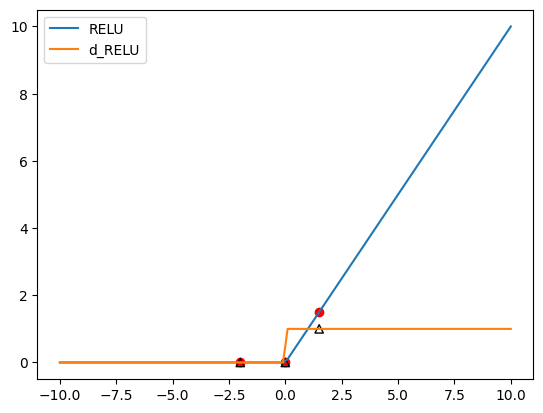

In [4]:
relu = lambda x: np.maximum(x, 0)
d_relu = lambda x: (x>0).astype(float)

print(x, relu(x), d_relu(x))

# PLOT ACTIVATION FUNCTION
x_t = np.linspace(-10, 10, 100)
plt.plot(x_t, relu(x_t), label="RELU")
plt.scatter(x, relu(x), color="red")
plt.plot(x_t, d_relu(x_t), label="d_RELU")
plt.scatter(x, d_relu(x), color="green", marker='^', facecolors='none', edgecolors='k')
plt.legend()
plt.show()

[-2.   0.   1.5] [0.119 0.5   0.818]


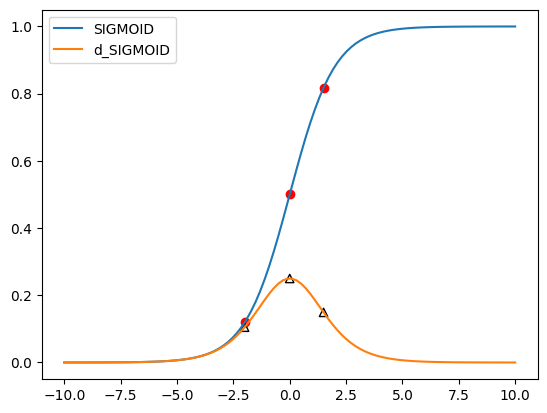

In [5]:
sigmoid = lambda x: 1/(1+np.exp(-x))
d_sigmoid = lambda x: sigmoid(x)*(1-sigmoid(x))


print(x, sigmoid(x))


# PLOT ACTIVATION FUNCTION
x_t = np.linspace(-10, 10, 100)
plt.plot(x_t, sigmoid(x_t), label="SIGMOID")
plt.scatter(x, sigmoid(x), color="red")
plt.plot(x_t, d_sigmoid(x_t), label="d_SIGMOID")
plt.scatter(x, d_sigmoid(x), color="green", marker='^', facecolors='none', edgecolors='k')
plt.legend()
plt.show()

[-2.   0.   1.5] [-0.964  0.     0.905]


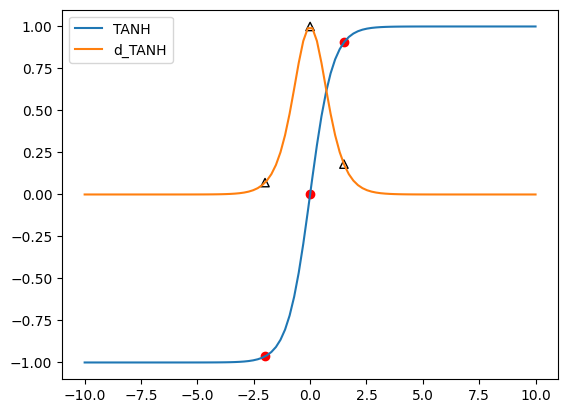

In [6]:
tanh = lambda x: (np.exp(x) - np.exp(-x))/(np.exp(x) + np.exp(-x))
d_tanh = lambda x: 1-tanh(x)**2
tanh(x)


print(x, tanh(x))


# PLOT ACTIVATION FUNCTION
x_t = np.linspace(-10, 10, 100)
plt.plot(x_t, tanh(x_t), label="TANH")
plt.scatter(x, tanh(x), color="red")
plt.plot(x_t, d_tanh(x_t), label="d_TANH")
plt.scatter(x, d_tanh(x), color="green", marker='^', facecolors='none', edgecolors='k')
plt.legend()
plt.show()

**2.** Considere la red neuronal con una capa oculta explícita $H$:

$$
Z_1 = W_1 X + B_1, \qquad H = \operatorname{ReLU}(Z_1), \qquad Y = W_2 H + B_2,
$$

donde

$$
X = \begin{pmatrix} 1 \\ -2 \end{pmatrix}, \qquad
W_1 = \begin{pmatrix} 1 & 0 \\ 2 & -1 \\ -1 & 1 \end{pmatrix}, \qquad
B_1 = \begin{pmatrix} 0 \\ 1 \\ 2 \end{pmatrix},
$$

$$
W_2 = \begin{pmatrix} 1 & -2 & 0 \\ 0 & 1 & 3 \end{pmatrix}, \qquad
B_2 = \begin{pmatrix} -1 \\ 2 \end{pmatrix}.
$$

Aquí $H$ es la capa oculta. Calcule $Z_1$, la capa oculta $H$ y la salida final $Y$.

In [7]:
X = np.array([1, -2], dtype=float)

W1 = np.array([
    [ 1,  0],
    [ 2, -1],
    [-1,  1],
], dtype=float)

B1 = np.array([0, 1, 2], dtype=float)

W2 = np.array([
    [1, -2, 0],
    [0,  1, 3],
], dtype=float)

B2 = np.array([-1, 2], dtype=float)

In [8]:
Z1 = W1@X + B1
print(f"Z1={Z1}")

H = relu(Z1)
print(f"H={H}")

Y = W2@H + B2
print(f"Y={Y}")

Z1=[ 1.  5. -1.]
H=[1. 5. 0.]
Y=[-10.   7.]


**3.** Sea

$$
Y = \begin{pmatrix} 1.2 \\ -0.4 \\ 2.0 \end{pmatrix}, \qquad
Y_* = \begin{pmatrix} 1 \\ 0 \\ 3 \end{pmatrix}, \qquad
E = \frac{1}{2} \lVert Y - Y_* \rVert^2.
$$

Calcule el error $E$ y el vector $\nabla_Y E$.

In [9]:
Y = np.array([1.2, -0.4, 2.0])

Y_star = np.array([1, 0, 3], dtype=float)

In [10]:
E = np.linalg.norm(Y-Y_star)**2/2

print(f"E={E}")

# check derivation in notes
# dE/dy = y - y*
dE = Y - Y_star
print(f"dE/dy={dE}")

E=0.5999999999999999
dE/dy=[ 0.2 -0.4 -1. ]


**4.** Para una capa con activación identidad, use

$$
W = \begin{pmatrix} 2 & -1 & 0 \\ 1 & 3 & -2 \end{pmatrix}, \qquad
X = \begin{pmatrix} 1 \\ -2 \\ 3 \end{pmatrix}, \qquad
\nabla_Y E = \begin{pmatrix} 4 \\ -1 \end{pmatrix}.
$$

Calcule $\nabla_W E$, $\nabla_B E$ y $\nabla_X E$.

In [11]:
# NOTATION: dE_Y = \nabla_Y E
W = np.array([
    [2, -1,  0],
    [1,  3, -2],
], dtype=float)

print(f"W.shape={W.shape}")

X = np.array([1, -2, 3], dtype=float).reshape(3, 1)
print(f"X.shape={X.shape}")

dE_Y = np.array([4, -1], dtype=float).reshape(2, 1)
print(f"dE_Y.shape={dE_Y.shape}")

W.shape=(2, 3)
X.shape=(3, 1)
dE_Y.shape=(2, 1)


In [12]:
# \nabla_W E
# check derivations on 11-nn.rnote

dE_W = dE_Y @X.T
dE_W

array([[ 4., -8., 12.],
       [-1.,  2., -3.]])

In [13]:
# \nabla_B E

dE_B = dE_Y
dE_B

array([[ 4.],
       [-1.]])

In [14]:
# \nabla_X E
# dE_Y.T to ensure dE_Y.shape = (1, 2) [as computation on 11-nn.rnote)
dE_X = dE_Y.T@W
dE_X

array([[ 7., -7.,  2.]])

**5.** En una capa de activación ReLU, se tiene

$$
X = \begin{pmatrix} -3 \\ 0.5 \\ 2 \\ -0.2 \end{pmatrix}, \qquad
\nabla_Y E = \begin{pmatrix} 1 \\ -4 \\ 0.5 \\ 3 \end{pmatrix}.
$$

Calcule $Y = \operatorname{ReLU}(X)$ y luego calcule $\nabla_X E$ usando el producto de Hadamard.

In [33]:
X = np.array([-3, 0.5, 2, -0.2]).reshape(4, 1)
print(f"X.shape={X.shape}")


dE_Y = np.array([1, -4, 0.5, 3]).reshape(4, 1)
print(f"dE_Y.shape={dE_Y.shape}")

X.shape=(4, 1)
dE_Y.shape=(4, 1)


In [34]:
# computation of Y = RELU(X)
relu = lambda x: np.maximum(x, 0)

relu(X)

array([[0. ],
       [0.5],
       [2. ],
       [0. ]])

In [36]:
# \nabla_X E
# dE_Y.T to match operation with dY_X
dY_X = np.array([
    [0, 0, 0, 0],
    [0, 1, 0, 0],
    [0, 0, 1, 0],
    [0, 0, 0, 0]
])
dE_X = dE_Y.T @ dY_X
dE_X_hadamard = dE_Y.T * np.diag(dY_X)
dE_X, dE_X_hadamard

(array([[ 0. , -4. ,  0.5,  0. ]]), array([[ 0. , -4. ,  0.5,  0. ]]))

**6.** En una capa de activación logística, considere

$$
X = \begin{pmatrix} 0 \\ \ln 3 \\ -\ln 2 \end{pmatrix}, \qquad
\nabla_Y E = \begin{pmatrix} 2 \\ -1 \\ 4 \end{pmatrix}.
$$

Calcule $\sigma(X)$, $\sigma'(X)$ y $\nabla_X E$, donde $\sigma'(x) = \sigma(x)\big(1 - \sigma(x)\big)$.

In [24]:
# The reshape are done to follow dimention on notes: 11-nn.rnote
X = np.array([0, np.log(3), -np.log(2)])

dE_Y = np.array([2, -1, 4], dtype=float).reshape(1, 3) 

In [25]:
# computation of \sigma(x)
sigmoid = lambda x: 1/(1+np.exp(-x))

sigmoid(X)

array([0.5  , 0.75 , 0.333])

In [26]:
# computation of \sigma '(x)
d_sigmoid = lambda x: sigmoid(x)*(1-sigmoid(x))

d_sigmoid(X)

array([0.25 , 0.188, 0.222])

In [27]:
# computation of \nabla_X E
# Asuming that Y = \sigma (X)

D=np.diag(d_sigmoid(X))

dE_X = dE_Y@D
dE_X

array([[ 0.5  , -0.188,  0.889]])